# 01 — Panel build

This notebook turns the raw rank panel into the research stack:

- `rank`: date × commodity × rank, with contract identity and flags.
- `contract`: date × real contract, with its full life and expiry proxy.
- `returns`: contract-level returns mapped back to rank slots.
- `pairs`: the nearest two eligible contracts per date/commodity.
- `spread`: dollar/log/percentage spreads for the selected pairs.
- `universe`: trailing liquidity metrics and threshold booleans (not applied).
- `episodes`: fixed-contract pair episodes with entry/exit spreads.
- `adjacent_pairs`: all eligible adjacent pairs (M1–M2, M2–M3, M3–M4) for robustness.
- `adjacent_spread`: dollar/log spreads for every adjacent pair.

All logic lives in `src/`; this notebook is the narrative and the save step.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))


In [2]:
import pandas as pd

from src import config, qa, viz
from src.load import load_rank_panel
from src.panel import build_all, liquidity_summary, save_panel

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)


## 1. Build the stack

Eligibility is locked to **no delivery month + at least 5 sessions before the
delivery-month start + `days_to_last_trading > 10`**. `D=5/20` can be passed to
`build_all` for robustness; the main run uses the defaults.


In [3]:
rank = load_rank_panel()
panels = build_all(rank)
{k: frame.shape for k, frame in panels.items()}


{'rank': (1013664, 23),
 'contract': (950626, 29),
 'returns': (1013664, 24),
 'pairs': (236186, 29),
 'spread': (236186, 30),
 'universe': (236186, 56),
 'episodes': (6664, 17),
 'adjacent_pairs': (610801, 29),
 'adjacent_spread': (610801, 30)}

## 2. Rank panel

The rank panel preserves the raw market fields and adds the real contract
identity, `is_roll`, `stale`, missing flags, and parsing results.


In [4]:
rank_panel = panels["rank"]
rank_panel[["date", "root", "rank", "contract_code", "settle", "is_roll"]].head(3)


,date,root,rank,contract_code,settle,is_roll
0,1986-01-02,BO,1,BOF86,21.62,False
1,1986-01-02,BO,2,BOH86,21.96,False
2,1986-01-02,BO,3,BOK86,22.20,False


## 3. Contract panel

Each real contract has one continuous life across ranks 4 → 3 → 2 → 1.
`last_trade_proxy` is the last date the contract appears in this extract;
`days_to_last_trading` is measured in trading sessions.


In [5]:
contract = panels["contract"]
print(f"{len(contract):,} contract-date rows; {contract['contract_key'].nunique():,} contracts")
contract[contract["contract_key"].eq("CL_CLK20")].tail(8)[
    ["date", "rank", "settle", "last_trade_proxy", "days_to_last_trading", "in_delivery_month"]
]


950,626 contract-date rows; 6,735 contracts


,date,rank,settle,last_trade_proxy,days_to_last_trading,in_delivery_month
796608,2020-04-09,1,22.76,2020-04-21,7,False
796704,2020-04-13,1,22.41,2020-04-21,6,False
796800,2020-04-14,1,20.11,2020-04-21,5,False
796896,2020-04-15,1,19.87,2020-04-21,4,False
796992,2020-04-16,1,19.87,2020-04-21,3,False
797088,2020-04-17,1,18.27,2020-04-21,2,False
797184,2020-04-20,1,-37.63,2020-04-21,1,False
797280,2020-04-21,1,10.01,2020-04-21,0,False


## 4. Return panel: roll-day returns use the new contract

On 2020-04-22 WTI rolls from CLK20 to CLM20. The correct rank-1 return uses
CLM20's previous price (11.57, when it was M2), not CLK20's 10.01. The difference
between `ret_rank` and `ret_naive` is the roll gap, not a return.


In [6]:
returns = panels["returns"]
returns[(returns["root"].eq("CL")) & (returns["rank"].eq(1)) & returns["date"].between("2020-04-17", "2020-04-23")][
    ["date", "contract_code", "settle", "ret_rank", "ret_naive"]
]


,date,contract_code,settle,ret_rank,ret_naive
852012,2020-04-17,CLK20,18.27,-0.080523,-0.080523
852108,2020-04-20,CLK20,-37.63,-3.059661,-3.059661
852204,2020-04-21,CLK20,10.01,-1.266011,-1.266011
852300,2020-04-22,CLM20,13.78,0.191011,0.376623
852396,2020-04-23,CLM20,16.50,0.197388,0.197388


In [7]:
qa.assert_unique_contract_date(contract)
qa.assert_rank_monotonic(rank_panel)
qa.assert_roll_sync(rank_panel)
qa.assert_return_mapping(returns)
qa.assert_contract_calendar(contract)
qa.assert_pair_adjacency(panels["pairs"])
print("all panel invariants passed")


all panel invariants passed


## 5. Pair episodes and spreads

The main pair is the two nearest eligible adjacent contracts. Around the
delivery buffer this shifts from M1–M2 to M2–M3; the mix over time is shown
below.


`pairs`/`spread` are the **main selected pair** (nearest two eligible
contracts). `adjacent_pairs`/`adjacent_spread` keep every eligible adjacent
pair for robustness and alternative-pair analysis; `is_main_pair` marks the
main subset.

In [8]:
pairs = panels["pairs"]
pairs["pair_rank_mix"].value_counts()


pair_rank_mix
M1-M2    139017
M2-M3     97169
Name: count, dtype: int64

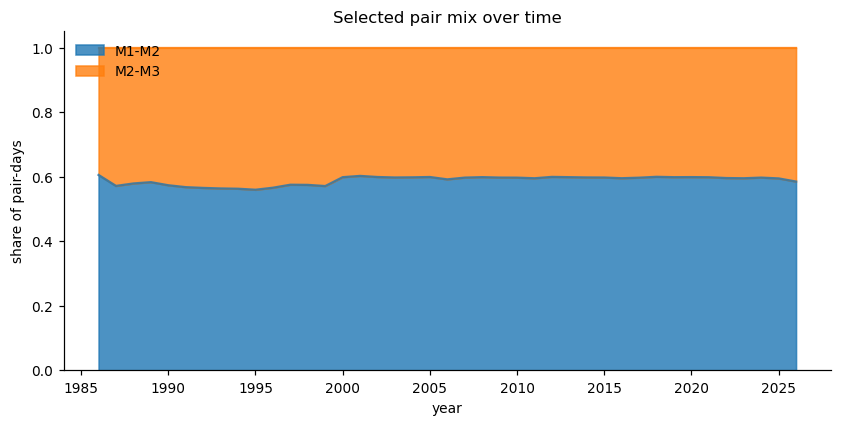

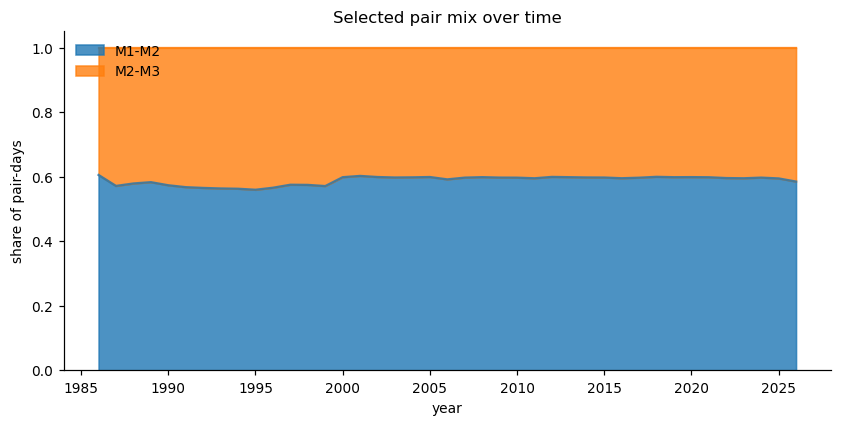

In [9]:
viz.plot_pair_mix(pairs)


In [10]:
episodes = panels["episodes"]
print(f"{len(episodes):,} episodes")
episodes.head(5)


6,664 episodes


,root,episode_id,contract_near,contract_far,pair_rank_mix,entry_date,exit_date,holding_days,n_obs,entry_spread,exit_spread,mean_spread,mean_liq_volume,min_liq_volume,mean_liq_oi,min_liq_oi,spread_change
0,BO,BO_0001,BOH86,BOK86,M2-M3,1986-01-02,1986-02-24,37,37,-0.24,-0.39,-0.382703,NaN,NaN,NaN,NaN,-0.15
1,BO,BO_0002,BOK86,BON86,M2-M3,1986-02-25,1986-04-24,42,42,-0.34,-0.32,-0.331905,1526.075000,1400.5,9169.425000,8649.5,0.02
2,BO,BO_0003,BON86,BOQ86,M2-M3,1986-04-25,1986-06-24,42,42,-0.12,-0.16,-0.141429,568.595238,423.5,5301.821429,4577.0,-0.04
3,BO,BO_0004,BOQ86,BOU86,M2-M3,1986-06-25,1986-07-25,22,22,-0.08,-0.15,-0.147727,420.500000,368.0,4121.590909,4003.0,-0.07
4,BO,BO_0005,BOU86,BOV86,M2-M3,1986-07-28,1986-08-25,21,21,-0.15,-0.10,-0.124286,560.880952,481.0,4856.095238,4250.5,0.05


The selected pair deliberately excludes the front contract when it is inside
the 10-session expiry buffer. The negative CL settlement is still in the rank
and contract panels and is flagged; a log spread using that leg is undefined,
while the dollar spread remains defined.


In [11]:
spread = panels["spread"]
spread[(spread["root"].eq("CL")) & spread["date"].between("2020-04-17", "2020-04-23")][
    ["date", "contract_near", "contract_far", "spread_dollar", "spread_log", "negative_price"]
]


,date,contract_near,contract_far,spread_dollar,spread_log,negative_price
198177,2020-04-17,CLM20,CLN20,-4.39,-0.161600,False
198201,2020-04-20,CLM20,CLN20,-5.85,-0.251804,False
198225,2020-04-21,CLM20,CLN20,-7.12,-0.479573,False
198249,2020-04-22,CLM20,CLN20,-6.91,-0.406432,False
198273,2020-04-23,CLM20,CLN20,-4.94,-0.261898,False


In [12]:
rank_panel.loc[rank_panel["negative_price"], ["date", "root", "rank", "contract_code", "settle"]]


,date,root,rank,contract_code,settle
852108,2020-04-20,CL,1,CLK20,-37.63


## 6. Liquidity / universe (threshold not applied)

The universe table carries trailing contract-level medians, rank-level fallback
flags, pair minimums, and booleans for 1k/5k/10k/20k. No row is removed here.
Choose the threshold after reviewing the diagnostics in notebook 00.


In [13]:
liquidity_summary(panels["universe"])


,threshold,pair_days,pass_volume_days,pass_oi_days,roots_pass_volume,roots_pass_oi
0,1000,236186,127944,180736,20,24
1,5000,236186,69301,151137,19,21
2,10000,236186,45043,125989,13,20
3,20000,236186,27121,91569,12,20


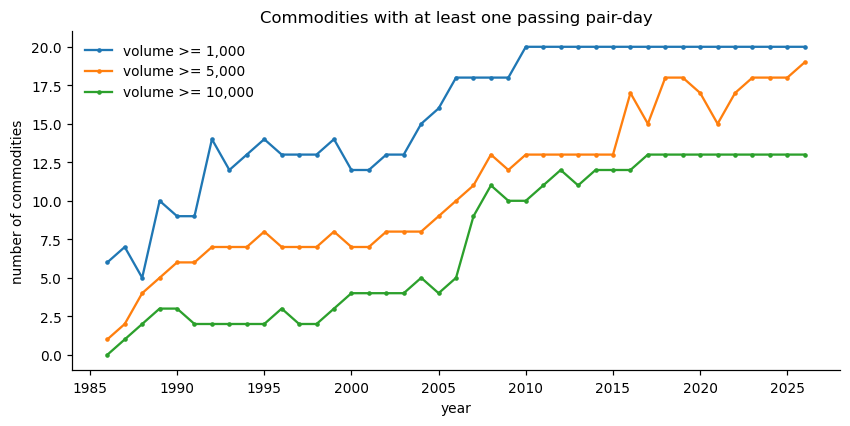

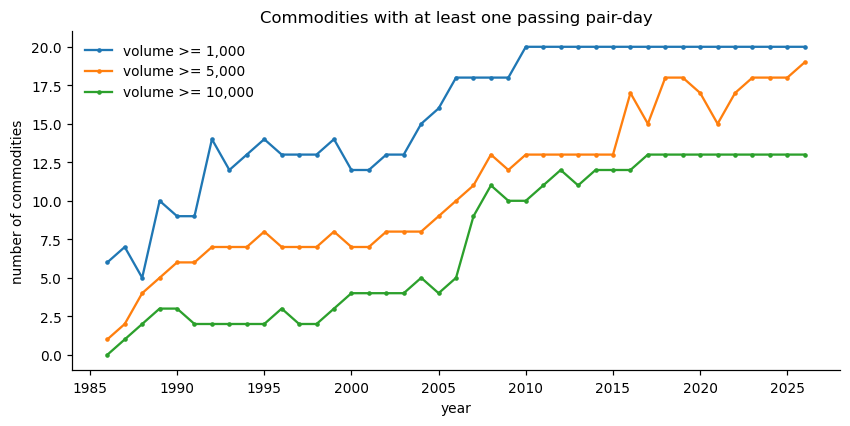

In [14]:
viz.plot_universe_counts(panels["universe"])


## 7. Save processed panels

The parquet files are written to `data/processed/` and are gitignored; they can
always be regenerated from this notebook.


In [15]:
paths = {name: save_panel(frame, name).relative_to(ROOT) for name, frame in panels.items()}
{k: str(v) for k, v in paths.items()}

{'rank': 'data/processed/rank.parquet',
 'contract': 'data/processed/contract.parquet',
 'returns': 'data/processed/returns.parquet',
 'pairs': 'data/processed/pairs.parquet',
 'spread': 'data/processed/spread.parquet',
 'universe': 'data/processed/universe.parquet',
 'episodes': 'data/processed/episodes.parquet',
 'adjacent_pairs': 'data/processed/adjacent_pairs.parquet',
 'adjacent_spread': 'data/processed/adjacent_spread.parquet'}

## 8. What this notebook does not do

- No signal definitions (A/B/C/D/H).
- No backtest, cost model, position sizing, or final liquidity threshold.
- No paper replication.

Those belong to the next phase. The data layer ends here: clean, validated, and
ready for research.
